# Fitting commuting generators to experimental CA1 place cells

Camera-ready version of notebook 11, with the commuting parametrisation of notebook 12:
$G_x = R^\top \Sigma_x R$, $G_y = R^\top \Sigma_y R$, exact path independence, no penalty.
On these data the penalised fit of notebook 11 reached 84 % of the split-half noise ceiling
at $\gamma = 1$ and blurred the fields; this fit reaches the ceiling.

Population: the single-field units of notebook 10 (`data/ca1_ratemaps.npz`), pooled over
animals and sessions. The ratemaps are in Hz and are scaled by one
global constant to the grid-cell file's maximum, a change of units that keeps the arena
normalisation identical across the two datasets. No smoothing beyond the source paper's
($\sigma = 1$ bin): more smoothing raises the correlation only by raising the ceiling.

Two questions. First, does the fit reproduce the maps, judged against the split-half
ceiling. Second, does it **extrapolate**: fit on the central three quarters of the arena,
generate the whole arena from the centre, and score the held-out outer ring against the
data, which no training step touched.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from expmap.fitting import CommutingGeneratorFit, generator_diagnostics, pixels_to_arena, sample_displacements

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
DATA = REPO_ROOT / "data" / "ca1_ratemaps.npz"
EVENTS = REPO_ROOT / "data" / "ca1_events.npz"
GRID_DATA = REPO_ROOT / "data" / "gc_ratmaps.npy"
OUTPUT = REPO_ROOT / "data" / "ca1_fit_commuting.npz"
sys.path.insert(0, str(REPO_ROOT / "notebooks" / "experimental_data"))

# Population rule (see notebook 10). None disables a criterion.
MAX_FIELDS = 1
MAX_BORDER = None  # 0.5 drops border-like units
MIN_STABILITY = None  # 0.5 drops units whose halves disagree

# Fit parameters, as for the grid cells (notebook 12).
N_STEPS = 20000
BATCH_SIZE = 32
MAX_STEP = 2
LR = 1e-3
WAVEVECTOR_LR = 1e-2
ARENA_SIZE = 1.0
SEED = 0

# Extrapolation: the fitted fraction of the arena side; the rest is the held-out ring.
FITTED_FRACTION = 0.75

In [2]:
d = np.load(DATA)
keep = d["n_fields"] <= MAX_FIELDS
if MAX_BORDER is not None:
    keep &= ~(d["border_score"] > MAX_BORDER)
if MIN_STABILITY is not None:
    keep &= d["stability"] >= MIN_STABILITY
experimental_hz = d["ratemaps"][keep]

grid_max = float(np.load(GRID_DATA).max())
SCALE = grid_max / experimental_hz.max()
experimental = (experimental_hz * SCALE).astype("float32")
ratemaps = torch.tensor(np.transpose(experimental, (1, 2, 0)))  # (bins_x, bins_y, n_units)

N_UNITS, N_BINS = experimental.shape[0], experimental.shape[1]
print(f"{N_UNITS} units, {N_BINS} x {N_BINS} bins, scale {SCALE:.4f} per Hz (max {experimental_hz.max():.1f} Hz -> {grid_max})")
print("units per animal:", {a: int((d["animal"][keep] == a).sum()) for a in np.unique(d["animal"])})

97 units, 32 x 32 bins, scale 0.0049 per Hz (max 40.6 Hz -> 0.1998630300365036)
units per animal: {np.str_('24101'): 10, np.str_('24116'): 6, np.str_('25398'): 50, np.str_('26019'): 12, np.str_('26191'): 19}


## Fit

loss 4.178e-05 -> 2.304e-05


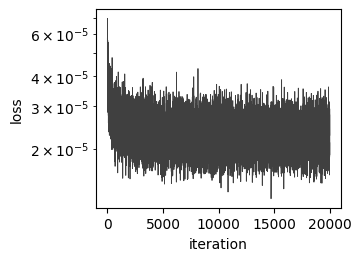

In [3]:
fit = CommutingGeneratorFit(n_units=N_UNITS, lr=LR, wavevector_lr=WAVEVECTOR_LR, seed=SEED)
loss_history = fit.fit(ratemaps, n_steps=N_STEPS, batch_size=BATCH_SIZE, max_step=MAX_STEP, arena_size=ARENA_SIZE, progress=False)
print(f"loss {np.mean(loss_history[:100]):.3e} -> {np.mean(loss_history[-100:]):.3e}")

fig, ax = plt.subplots(figsize=(3.5, 2.5), layout="constrained")
ax.semilogy(loss_history, "k", linewidth=0.6, alpha=0.75)
ax.set_xlabel("iteration")
ax.set_ylabel("loss")
fig.savefig(FIGURE_DIR / "ca1_commuting_loss_curve.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_commuting_loss_curve.png", dpi=200, bbox_inches="tight")

## Reconstruction within the arena

Generated from the population vector at the arena centre. The relative error has a floor
from the data not being equinorm (an orthogonal model cannot vary $\|p\|$), computed as
in notebook 11; the per-unit correlation is the scale-free measure.

relative reconstruction error 52.1% (equinorm floor 25.1%); per unit median 55.4%
per-unit correlation generated vs data: median 0.82, 10/90 pct 0.69/0.89


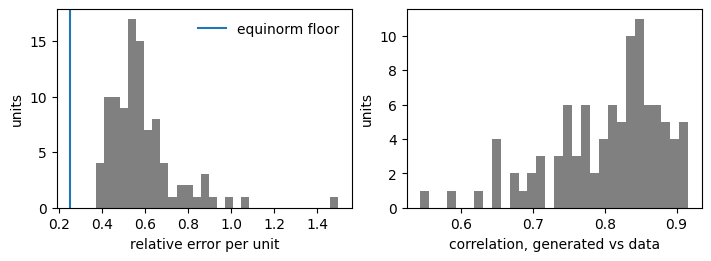

In [4]:
centre = ratemaps[N_BINS // 2, N_BINS // 2]
generated = fit.generate(centre, n_bins=N_BINS, extent=1.0, arena_size=ARENA_SIZE).numpy()

norm_map = np.sqrt((experimental**2).sum(axis=0))
equinorm_floor = np.sqrt(((experimental * (norm_map.mean() / norm_map - 1)) ** 2).mean()) / np.sqrt((experimental**2).mean())
residual = generated - experimental
relative = np.sqrt((residual**2).mean()) / np.sqrt((experimental**2).mean())
per_unit = np.sqrt((residual**2).mean(axis=(1, 2))) / np.sqrt((experimental**2).mean(axis=(1, 2)))
correlation = np.array([np.corrcoef(g.ravel(), e.ravel())[0, 1] for g, e in zip(generated, experimental)])
print(f"relative reconstruction error {relative:.1%} (equinorm floor {equinorm_floor:.1%}); per unit median {np.median(per_unit):.1%}")
print(f"per-unit correlation generated vs data: median {np.median(correlation):.2f}, 10/90 pct {np.percentile(correlation, 10):.2f}/{np.percentile(correlation, 90):.2f}")

fig, axs = plt.subplots(1, 2, figsize=(7, 2.5), layout="constrained")
axs[0].hist(per_unit, bins=30, color="0.5")
axs[0].axvline(equinorm_floor, color="C0", label="equinorm floor")
axs[0].set_xlabel("relative error per unit")
axs[0].set_ylabel("units")
axs[0].legend(frameon=False)
axs[1].hist(correlation, bins=30, color="0.5")
axs[1].set_xlabel("correlation, generated vs data")
axs[1].set_ylabel("units")
fig.savefig(FIGURE_DIR / "ca1_commuting_errors.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_commuting_errors.png", dpi=200, bbox_inches="tight")

### Data and generation side by side

Units sorted by reconstruction correlation, best to worst, evenly sampled. Rows alternate
data and generation; each pair shares the unit's own scale. Maps in arena coordinates.

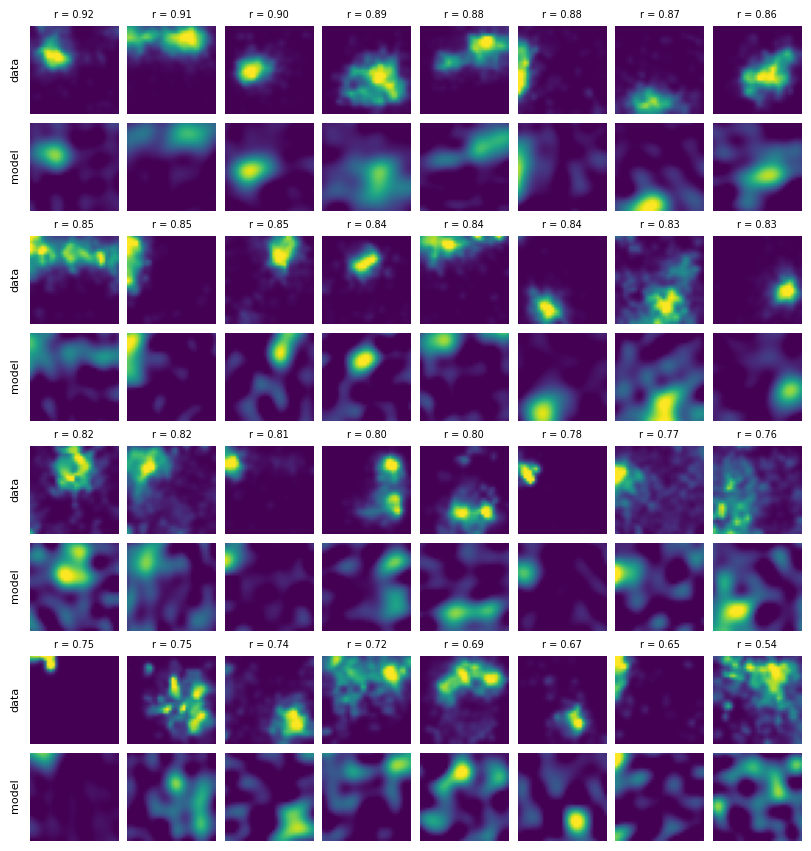

In [5]:
from galleries import gallery  # noqa: E402

fig = gallery(experimental, generated, correlation, np.ones(N_UNITS, bool))
fig.savefig(FIGURE_DIR / "ca1_commuting_ratemaps.png", dpi=150, bbox_inches="tight")

## Against the noise ceiling

A ratemap from a 20-30 min session is a noisy estimate, so no model can reproduce it to
arbitrary precision. The split-half correlation of a unit, between ratemaps from the two
halves of its session, is the ceiling for predicting one half from anything. The model's
correlation with each half is compared against it; `ca1.py` builds the half maps with the
same preprocessing.

split-half ceiling: median 0.85;  model vs halves: median 0.78;  ratio median 0.94;  model above ceiling for 24 of 96 units


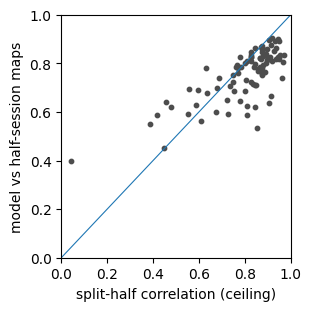

In [6]:
from ca1 import arena_box, load_events, population_ratemaps, preprocess_position, ratemap, select_units  # noqa: E402

sessions, units = load_events(EVENTS)
rate_passing = select_units(units, tuple(d["rate_range"]))
_, _, information = population_ratemaps(sessions, units, rate_passing, N_BINS)
chosen = rate_passing[information >= float(d["info_threshold"])][keep]  # same units, same order as `experimental`

cache = {}
halves = []
for i in chosen:
    u, s = units[i], sessions[units[i].session]
    if u.session not in cache:
        xy, valid = preprocess_position(s)
        cache[u.session] = (xy, valid, arena_box(xy, valid))
    xy, valid, box = cache[u.session]
    first = s.t < s.t[-1] / 2
    halves.append([np.nan_to_num(ratemap(u.spike_t, s.t, xy, valid & half, box, N_BINS)[0]) for half in (first, ~first)])
del sessions, units, cache


def corr(a, b):
    return np.corrcoef(a.ravel(), b.ravel())[0, 1]


ceiling = np.array([corr(a, b) for a, b in halves])
model_half = np.array([0.5 * (corr(g, a) + corr(g, b)) for g, (a, b) in zip(generated, halves)])
ok = np.isfinite(ceiling) & np.isfinite(model_half)
print(f"split-half ceiling: median {np.median(ceiling[ok]):.2f};  model vs halves: median {np.median(model_half[ok]):.2f};  "
      f"ratio median {np.median(model_half[ok] / ceiling[ok]):.2f};  model above ceiling for {(model_half[ok] > ceiling[ok]).sum()} of {ok.sum()} units")

fig, ax = plt.subplots(figsize=(3, 3), layout="constrained")
ax.scatter(ceiling[ok], model_half[ok], s=10, color="0.3")
ax.plot([0, 1], [0, 1], color="C0", linewidth=0.8)
ax.set_xlabel("split-half correlation (ceiling)")
ax.set_ylabel("model vs half-session maps")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
fig.savefig(FIGURE_DIR / "ca1_commuting_ceiling.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_commuting_ceiling.png", dpi=200, bbox_inches="tight")

## What the fit recovered

Path independence is exact, so the diagnostics are a consistency check. The wavevectors are
the fitted spectrum: App. H's place-like fields come from a Gaussian cloud of wavevectors,
which is what to compare against. The one-step error on displacements up to 8 px, longer
than any training step, shows how transport composes.

  commutator_rms             1.097e-05
  Gx_rms                     5.291e-01
  Gx_symmetric_fraction      1.170e-07
  Gy_rms                     5.138e-01
  Gy_symmetric_fraction      1.186e-07
  one-step relative error by step length (px): 1: 22% 2: 35% 3: 43% 4: 47% 5: 50% 6: 52% 7: 53% 8: 54%


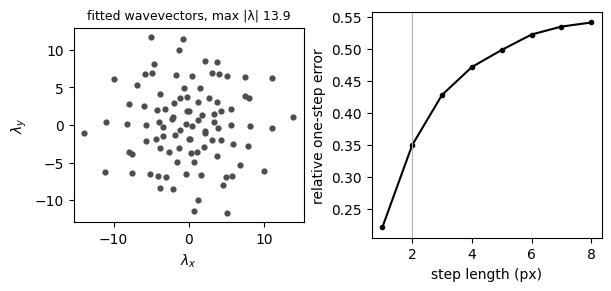

In [7]:
for name, value in generator_diagnostics(fit).items():
    print(f"  {name:26s} {value:.3e}")

generator = torch.Generator().manual_seed(SEED + 1)
start, end = sample_displacements(N_BINS, 20000, max_step=8, generator=generator)
dr = pixels_to_arena(end - start, N_BINS, ARENA_SIZE)
with torch.no_grad():
    predicted = fit.transport(ratemaps[start[:, 0], start[:, 1]], dr)
target = ratemaps[end[:, 0], end[:, 1]]
length = (end - start).abs().max(dim=1).values
error = ((predicted - target) ** 2).mean(dim=1).sqrt() / target.pow(2).mean(dim=1).sqrt()
step_error = np.array([float(error[length == n].mean()) for n in range(9)])
print("  one-step relative error by step length (px):", " ".join(f"{n}: {e:.0%}" for n, e in enumerate(step_error) if n))

wavevectors = fit.wavevectors.detach().numpy()
fig, axs = plt.subplots(1, 2, figsize=(6, 2.8), layout="constrained")
axs[0].scatter(wavevectors[:, 0], wavevectors[:, 1], s=12, color="0.3")
axs[0].scatter(-wavevectors[:, 0], -wavevectors[:, 1], s=12, color="0.3")
axs[0].set_aspect("equal")
axs[0].set_xlabel(r"$\lambda_x$")
axs[0].set_ylabel(r"$\lambda_y$")
axs[0].set_title(f"fitted wavevectors, max |λ| {np.abs(wavevectors).max():.1f}", fontsize=9)
axs[1].plot(range(1, 9), step_error[1:], "k.-")
axs[1].set_xlabel("step length (px)")
axs[1].set_ylabel("relative one-step error")
axs[1].axvline(MAX_STEP, color="0.7", linewidth=0.8)
fig.savefig(FIGURE_DIR / "ca1_commuting_generators.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_commuting_generators.png", dpi=200, bbox_inches="tight")

## Extrapolation: fit the centre, predict the ring

The fit sees only the central square of side `FITTED_FRACTION` of the arena and generates
the whole arena from its centre; the pixel size is unchanged, so the outer ring is scored
at native resolution against data no training step touched. Fields whose flank enters the
fitted square can be continued outward; a field lying entirely in the ring is unconstrained
by anything the fit saw, so units are also split by where their peak lies. Chance level
for the outer-ring correlation is the same statistic with units shuffled.

fitted square: pixels 4..28 of 32; 38 of 97 units peak in the held-out ring
correlation inside the fitted square: median 0.85
correlation on the held-out ring: median 0.68 (peak in ring 0.74, peak inside 0.65; chance -0.05)
relative error on the ring 74.2%; a flat map at each unit's fitted-square mean gives 98.8%


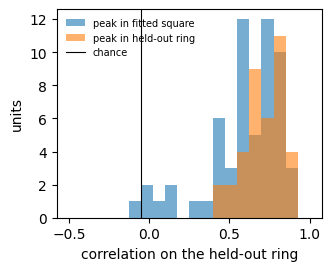

In [8]:
lo = int(round(N_BINS * (1 - FITTED_FRACTION) / 2))
hi = N_BINS - lo
inner = np.zeros((N_BINS, N_BINS), bool)
inner[lo:hi, lo:hi] = True
crop = ratemaps[lo:hi, lo:hi]

# the crop spans [-FITTED_FRACTION, FITTED_FRACTION] of the arena, so its pixel is the arena's pixel
crop_fit = CommutingGeneratorFit(n_units=N_UNITS, lr=LR, wavevector_lr=WAVEVECTOR_LR, seed=SEED)
crop_loss = crop_fit.fit(crop, n_steps=N_STEPS, batch_size=BATCH_SIZE, max_step=MAX_STEP, arena_size=FITTED_FRACTION * ARENA_SIZE, progress=False)
extrapolated = crop_fit.generate(crop[(hi - lo) // 2, (hi - lo) // 2], n_bins=N_BINS, extent=1.0, arena_size=ARENA_SIZE).numpy()

peak = np.array([np.unravel_index(m.argmax(), m.shape) for m in experimental])
field_outside = ~inner[peak[:, 0], peak[:, 1]]


def ring_corr(model):
    return np.array([np.corrcoef(g[~inner], e[~inner])[0, 1] for g, e in zip(model, experimental)])


outer_corr = ring_corr(extrapolated)
inner_corr = np.array([np.corrcoef(g[inner], e[inner])[0, 1] for g, e in zip(extrapolated, experimental)])
outer_error = np.sqrt(((extrapolated - experimental)[:, ~inner] ** 2).mean()) / np.sqrt((experimental[:, ~inner] ** 2).mean())
flat = np.broadcast_to(experimental[:, inner].mean(1)[:, None, None], experimental.shape)
flat_error = np.sqrt(((flat - experimental)[:, ~inner] ** 2).mean()) / np.sqrt((experimental[:, ~inner] ** 2).mean())
rng = np.random.default_rng(SEED)
chance = np.mean([np.median(ring_corr(extrapolated[rng.permutation(N_UNITS)])) for _ in range(20)])

print(f"fitted square: pixels {lo}..{hi} of {N_BINS}; {field_outside.sum()} of {N_UNITS} units peak in the held-out ring")
print(f"correlation inside the fitted square: median {np.median(inner_corr):.2f}")
print(f"correlation on the held-out ring: median {np.median(outer_corr):.2f} (peak in ring {np.median(outer_corr[field_outside]):.2f}, "
      f"peak inside {np.median(outer_corr[~field_outside]):.2f}; chance {chance:.2f})")
print(f"relative error on the ring {outer_error:.1%}; a flat map at each unit's fitted-square mean gives {flat_error:.1%}")

fig, ax = plt.subplots(figsize=(3.2, 2.6), layout="constrained")
ax.hist(outer_corr[~field_outside], bins=20, range=(-0.5, 1), alpha=0.6, label="peak in fitted square")
ax.hist(outer_corr[field_outside], bins=20, range=(-0.5, 1), alpha=0.6, label="peak in held-out ring")
ax.axvline(chance, color="k", linewidth=0.8, label="chance")
ax.set_xlabel("correlation on the held-out ring")
ax.set_ylabel("units")
ax.legend(frameon=False, fontsize=7)
fig.savefig(FIGURE_DIR / "ca1_commuting_extrapolation_hist.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_commuting_extrapolation_hist.png", dpi=200, bbox_inches="tight")

### Held-out ring, units whose field peaks in it

Data above, extrapolation below, white box = fitted square. Sorted by ring correlation.

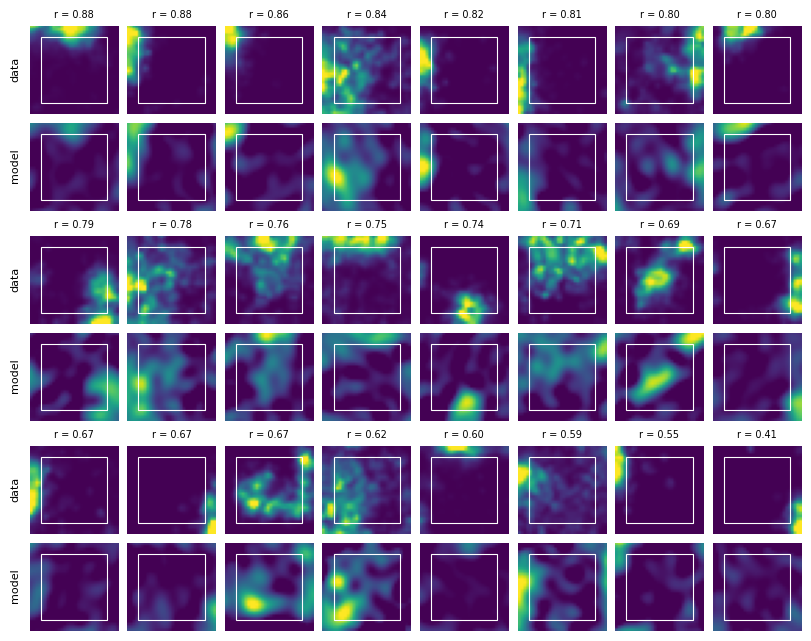

In [9]:
fig = gallery(experimental, extrapolated, outer_corr, field_outside, box=(lo, hi), n_show=24)
fig.savefig(FIGURE_DIR / "ca1_commuting_extrapolation.png", dpi=150, bbox_inches="tight")

## Save

In [10]:
np.savez_compressed(
    OUTPUT,
    Gx=fit.Gx.detach().numpy(),
    Gy=fit.Gy.detach().numpy(),
    R=fit.R.detach().numpy(),
    wavevectors=wavevectors,
    loss_history=np.array(loss_history),
    experimental=experimental,
    generated=generated,
    scale=SCALE,
    unit_mask=keep,
    seed=SEED,
    n_steps=N_STEPS,
    step_error=step_error,
    relative_error=relative,
    correlation=correlation,
    split_half_ceiling=ceiling,
    model_vs_halves=model_half,
    fitted_fraction=FITTED_FRACTION,
    inner=inner,
    extrapolated=extrapolated,
    crop_Gx=crop_fit.Gx.detach().numpy(),
    crop_Gy=crop_fit.Gy.detach().numpy(),
    crop_loss_history=np.array(crop_loss),
    field_outside=field_outside,
    outer_correlation=outer_corr,
    outer_correlation_chance=chance,
)
print(f"saved {OUTPUT.name}")

saved ca1_fit_commuting.npz
